# ANN and CNN — FAO land suitability
**Virginia tobacco, Regions I & II**

Fourth and fifth models, after the ordinal logistic baseline, the random forest and
XGBoost. Same seed, same stratified-block holdout, same ten rule predictors.

## The architectural question this notebook answers

A CNN convolves over spatial neighbourhoods. The feature matrix is **one row per grid
cell**, so there is no neighbourhood to convolve over — a CNN on that input is just an
MLP with extra steps, and claiming otherwise would not survive review.

So two models are built:

| | input | sees |
|---|---|---|
| **ANN (MLP)** | 10 features of the cell | the cell only |
| **CNN** | `k × k × 10` patch from the aligned grid | the cell **and its neighbourhood** |

The patches are extracted from `labeled/` by rebuilding the 30 m raster stack, so the CNN
has genuine spatial context: local terrain roughness, texture gradients, how wet the
surrounding catchment is.

**The expected result, stated before running:** the CNN will roughly match the MLP and not
beat it, because the FAO label is a *pointwise* function of the centre cell's own values.
Neighbourhood context cannot add information the label does not contain. If that is what
happens, it is a reportable negative finding that settles the architecture question with
evidence rather than assertion.

Outputs are tagged `ann_` / `cnn_` into `nn_outputs/`.

## Setup

In [1]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "tensorflow"])
subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", "tensorflow"])

CompletedProcess(args=['c:\\Users\\user\\AppData\\Local\\Programs\\Python\\Python311\\python.exe', '-m', 'pip', 'install', '--no-cache-dir', 'tensorflow'], returncode=0)

In [2]:
import sys, subprocess
print("kernel python:", sys.executable)
print("version:", sys.version)
try:
    import numpy; print("numpy", numpy.__version__)
except Exception as e: print("numpy FAILED:", e)
try:
    import tensorflow as tf; print("tensorflow", tf.__version__)
except Exception as e:
    print("tensorflow FAILED:", type(e).__name__, e)
print()
print(subprocess.run([sys.executable, "-m", "pip", "show", "tensorflow"],
                     capture_output=True, text=True).stdout or "NOT installed in this kernel")

kernel python: c:\Users\user\AppData\Local\Programs\Python\Python311\python.exe
version: 3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]
numpy 2.4.3
tensorflow 2.21.0

Name: tensorflow
Version: 2.21.0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, setuptools, six, termcolor, typing_extensions, wrapt
Required-by: 



In [3]:
# !pip install tensorflow scikit-learn pyarrow matplotlib -q
import os, time, warnings, json, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, cohen_kappa_score, confusion_matrix,
                             accuracy_score, classification_report)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

pd.set_option("display.width", 200, "display.max_columns", 60)
print("tensorflow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

SRC       = r"D:\Projects\capstone"
DATA_PATH = os.path.join(SRC, "feature_matrix.parquet")
LABELED   = os.path.join(SRC, "labeled")
OUT_DIR   = os.path.join(SRC, "nn_outputs")
WORK      = os.path.join(SRC, "nn_work")          # patch memmaps live here
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(WORK, exist_ok=True)
p_out = lambda n: os.path.join(OUT_DIR, n)

TARGET, BLOCK, REGION = "fao_class", "spatial_block", "region"
ORDER = ["N", "S3", "S2", "S1"]
SEED  = 42

PATCH   = 7          # k x k neighbourhood for the CNN (odd number)
CNN_N   = 120_000    # training cells used for the CNN (memory bound)
EPOCHS  = 100
BATCH   = 512
PATIENCE = 12

code_of = {c: i for i, c in enumerate(ORDER)}
np.random.seed(SEED); tf.random.set_seed(SEED)
T0 = time.time()
tick = lambda m: print(f"[{(time.time()-T0)/60:6.1f} min] {m}", flush=True)
print("ready")

tensorflow 2.21.0 | GPU: []
ready


## Stage 0 — Load and reproduce the same spatial holdout

Must match the other three notebooks: train 303,096 / holdout 72,026 over 105 blocks.

In [4]:
tick("loading")
df = pd.read_parquet(DATA_PATH).dropna(subset=[TARGET]).reset_index(drop=True)

rng = np.random.default_rng(SEED)
test_blocks = []
for _, g in df.groupby(REGION):
    has_rare = g.groupby(BLOCK)[TARGET].apply(lambda s: (s == ORDER[-1]).any())
    for flag in (True, False):
        b = has_rare[has_rare == flag].index.to_numpy()
        if len(b):
            test_blocks += list(rng.choice(b, size=max(1, int(0.2*len(b))), replace=False))

is_test = df[BLOCK].isin(test_blocks)
train = df[~is_test].reset_index(drop=True)
test  = df[is_test].reset_index(drop=True)
print(f"train {len(train):,} | holdout {len(test):,} over {len(test_blocks)} blocks")
pd.DataFrame({"train": train[TARGET].value_counts().reindex(ORDER),
              "holdout": test[TARGET].value_counts().reindex(ORDER)})

[   2.6 min] loading
train 303,096 | holdout 72,026 over 105 blocks


,train,holdout
fao_class,,
N,96141,23859
S3,95705,24295
S2,98014,21986
S1,13236,1886


## Stage 1 — Features, scaling, class weights

**This is where normalisation finally happens.** Section 3.4.1 promised it, and the tree
models did not need it — but a neural network does, or the high-magnitude predictors
(rainfall in mm, elevation in m) dominate the gradient over pH and NDMI.

The scaler is fitted on **training rows only**; the holdout is transformed with the
training statistics. Fitting on all data would leak the holdout's distribution.

In [5]:
RULE = ["soil_ph", "slope_pct", "temp_gs_mean", "soc", "cec", "sand_pct",
        "clay_pct", "ndmi_median", "twi", "sunshine_rad"]
FEATURES = [c for c in RULE if c in df.columns]
assert len(FEATURES) == 10

scaler = StandardScaler().fit(train[FEATURES])
Xtr = scaler.transform(train[FEATURES]).astype("float32")
Xte = scaler.transform(test[FEATURES]).astype("float32")
ytr = train[TARGET].map(code_of).to_numpy()
yte = test[TARGET].map(code_of).to_numpy()
blocks_tr = train[BLOCK].to_numpy()

cw = compute_class_weight("balanced", classes=np.arange(len(ORDER)), y=ytr)
CLASS_W = {i: float(w) for i, w in enumerate(cw)}

print(f"{len(FEATURES)} features | train {Xtr.shape} | holdout {Xte.shape}")
pd.DataFrame({"feature": FEATURES,
              "train_mean": scaler.mean_.round(3),
              "train_sd": np.sqrt(scaler.var_).round(3)})

10 features | train (303096, 10) | holdout (72026, 10)


,feature,train_mean,train_sd
0,soil_ph,5.768,0.437
1,slope_pct,14.523,18.023
2,temp_gs_mean,25.724,1.739
3,soc,22.803,11.328
4,cec,21.882,4.534
5,sand_pct,38.947,4.047
6,clay_pct,31.650,2.889
7,ndmi_median,0.226,0.161
8,twi,7.296,1.695
9,sunshine_rad,16.080,1.915


## Stage 2 — Blocked inner validation split

Early stopping needs a validation set, and it must respect blocks for the same reason it
did with boosting: adjacent cells are near-duplicates, so a random split would let
validation loss keep falling after the model stopped generalising.

In [6]:
ub = np.unique(blocks_tr)
val_b = rng.choice(ub, size=max(1, int(0.2*len(ub))), replace=False)
is_val = np.isin(blocks_tr, val_b)

Xa, ya = Xtr[~is_val], ytr[~is_val]
Xb, yb = Xtr[is_val],  ytr[is_val]
print(f"inner train {len(Xa):,} ({len(ub)-len(val_b)} blocks) | "
      f"inner valid {len(Xb):,} ({len(val_b)} blocks)")
print("inner valid classes:", dict(zip(ORDER, np.bincount(yb, minlength=4))))

inner train 249,841 (342 blocks) | inner valid 53,255 (85 blocks)
inner valid classes: {'N': np.int64(18200), 'S3': np.int64(15709), 'S2': np.int64(16036), 'S1': np.int64(3310)}


## Stage 3 — ANN (multilayer perceptron)

Three hidden layers with batch normalisation and dropout. Batch norm stabilises training
with ten inputs on very different scales even after standardisation; dropout is the main
regulariser.

In [7]:
def build_mlp(n_in, n_out=len(ORDER), seed=SEED):
    tf.random.set_seed(seed)
    m = keras.Sequential([
        layers.Input(shape=(n_in,)),
        layers.Dense(128, activation="relu"), layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),  layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(n_out, activation="softmax"),
    ], name="ann")
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

CB = lambda: [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                  restore_best_weights=True, verbose=0),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=5, min_lr=1e-5, verbose=0),
]

tick("training ANN")
ann = build_mlp(len(FEATURES))
ann.summary()
hist = ann.fit(Xa, ya, validation_data=(Xb, yb), epochs=EPOCHS,
               batch_size=BATCH, class_weight=CLASS_W, callbacks=CB(), verbose=0)
tick(f"stopped after {len(hist.history['loss'])} epochs")

[   2.7 min] training ANN


Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,644 (49.39 KB)

 Trainable params: 12,260 (47.89 KB)

 Non-trainable params: 384 (1.50 KB)

[   5.0 min] stopped after 78 epochs


### Training curves

Validation loss is on held-out **blocks**. If it bottoms out and rises, the epochs past the
minimum are memorisation — early stopping restores the best weights.

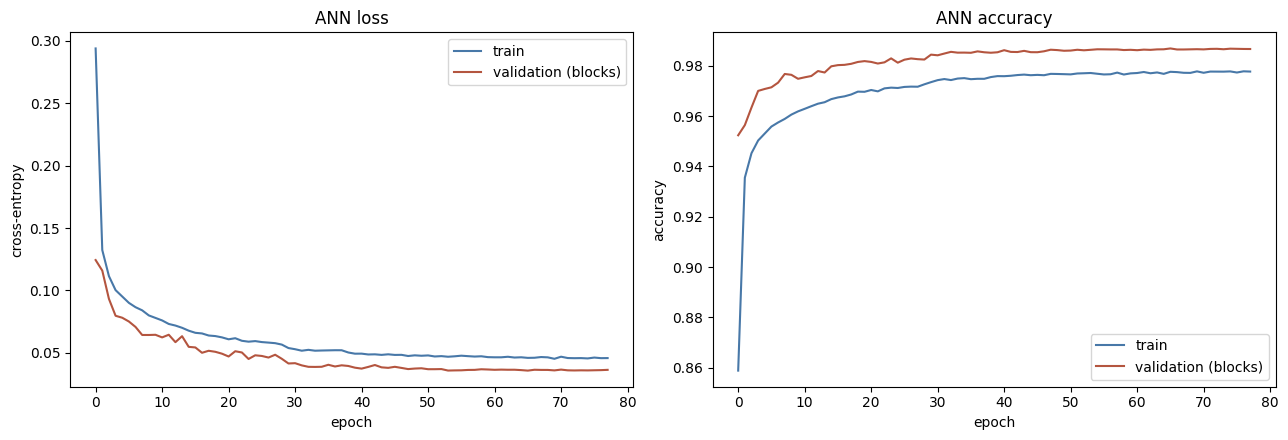

best epoch 65  val_loss 0.03583  val_acc 0.9869


In [8]:
h = hist.history
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(h["loss"], label="train", color="#4878A8")
axes[0].plot(h["val_loss"], label="validation (blocks)", color="#B4553F")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy")
axes[0].set_title("ANN loss"); axes[0].legend()
axes[1].plot(h["accuracy"], label="train", color="#4878A8")
axes[1].plot(h["val_accuracy"], label="validation (blocks)", color="#B4553F")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].set_title("ANN accuracy"); axes[1].legend()
fig.tight_layout(); fig.savefig(p_out("ann_training_curve.png"), dpi=170); plt.show()

pd.DataFrame(h).to_csv(p_out("ann_training_history.csv"), index=False)
best = int(np.argmin(h["val_loss"]))
print(f"best epoch {best}  val_loss {h['val_loss'][best]:.5f}  "
      f"val_acc {h['val_accuracy'][best]:.4f}")

## Stage 4 — ANN holdout performance

In [9]:
def scores(t, p, label):
    return dict(subset=label, n=len(t), accuracy=accuracy_score(t, p),
                macroF1=f1_score(t, p, average="macro"),
                kappa=cohen_kappa_score(t, p),
                kappa_quadratic=cohen_kappa_score(t, p, weights="quadratic"),
                within_one=float(np.mean(np.abs(t - p) <= 1)))

ann_pred = ann.predict(Xte, batch_size=4096, verbose=0).argmax(1)
rows = [scores(yte, ann_pred, "ANN holdout (all)")]
for r in sorted(test[REGION].unique()):
    m = (test[REGION] == r).to_numpy()
    rows.append(scores(yte[m], ann_pred[m], f"ANN holdout Region {r}"))
ann_res = pd.DataFrame(rows)
ann_res.to_csv(p_out("ann_holdout_scores.csv"), index=False)
ann_res.round(4)

,subset,n,accuracy,macroF1,kappa,kappa_quadratic,within_one
0,ANN holdout (all),72026,0.9881,0.9889,0.9826,0.9920,1.0
1,ANN holdout Region I,24685,0.9875,0.9883,0.9822,0.9931,1.0
2,ANN holdout Region II,47341,0.9884,0.9865,0.9826,0.9910,1.0


In [10]:
cm = pd.DataFrame(confusion_matrix(yte, ann_pred, labels=range(len(ORDER))),
                  index=[f"true_{c}" for c in ORDER],
                  columns=[f"pred_{c}" for c in ORDER])
cm.to_csv(p_out("ann_holdout_confusion.csv"))
far = int(sum(cm.iloc[a, b] for a in range(4) for b in range(4) if abs(a-b) > 1))
print("recall per class (%):")
print((cm.div(cm.sum(axis=1), axis=0)*100).round(1).to_string())
print(f"\ncells two or more classes apart: {far:,}")
print()
print(classification_report(yte, ann_pred, target_names=ORDER, digits=3))
cm

recall per class (%):
         pred_N  pred_S3  pred_S2  pred_S1
true_N     99.4      0.6      0.0      0.0
true_S3     0.2     97.7      2.1      0.0
true_S2     0.0      0.5     99.3      0.1
true_S1     0.0      0.0      0.0    100.0

cells two or more classes apart: 0

              precision    recall  f1-score   support

           N      0.998     0.994     0.996     23859
          S3      0.989     0.977     0.983     24295
          S2      0.977     0.993     0.985     21986
          S1      0.983     1.000     0.992      1886

    accuracy                          0.988     72026
   macro avg      0.987     0.991     0.989     72026
weighted avg      0.988     0.988     0.988     72026



,pred_N,pred_S3,pred_S2,pred_S1
true_N,23709,150,0,0
true_S3,56,23734,505,0
true_S2,0,115,21839,32
true_S1,0,0,0,1886


## Stage 5 — Spatially blocked cross-validation (ANN)

Each fold refits from scratch with its own scaler, fitted on that fold's training rows
only. Re-using one global scaler across folds would leak.

In [11]:
tick("ANN blocked CV")
cv_rows = []
for k, (tr_i, va_i) in enumerate(StratifiedGroupKFold(5, shuffle=True,
        random_state=SEED).split(Xtr, ytr, blocks_tr), 1):
    sc = StandardScaler().fit(train[FEATURES].iloc[tr_i])
    xa = sc.transform(train[FEATURES].iloc[tr_i]).astype("float32")
    xv = sc.transform(train[FEATURES].iloc[va_i]).astype("float32")
    m = build_mlp(len(FEATURES), seed=SEED + k)
    m.fit(xa, ytr[tr_i], validation_split=0.1, epochs=EPOCHS, batch_size=BATCH,
          class_weight=CLASS_W, callbacks=CB(), verbose=0)
    p = m.predict(xv, batch_size=4096, verbose=0).argmax(1)
    cv_rows.append(dict(fold=k, macroF1=f1_score(ytr[va_i], p, average="macro"),
                        kappa=cohen_kappa_score(ytr[va_i], p),
                        kappa_quadratic=cohen_kappa_score(ytr[va_i], p,
                                                          weights="quadratic")))
    tick(f"  fold {k}: macroF1={cv_rows[-1]['macroF1']:.4f}")
    keras.backend.clear_session()

ann_cv = pd.DataFrame(cv_rows)
ann_cv.loc["mean"] = ann_cv.mean(numeric_only=True)
ann_cv.loc["sd"] = pd.DataFrame(cv_rows).std(numeric_only=True)
ann_cv.to_csv(p_out("ann_cv.csv"))
ann_cv.round(4)

[   5.0 min] ANN blocked CV
[   6.6 min]   fold 1: macroF1=0.9737

[   8.7 min]   fold 2: macroF1=0.9808
[  10.7 min]   fold 3: macroF1=0.9876
[  13.2 min]   fold 4: macroF1=0.9839
[  15.7 min]   fold 5: macroF1=0.9844


,fold,macroF1,kappa,kappa_quadratic
0,1.0000,0.9737,0.9572,0.9825
1,2.0000,0.9808,0.9794,0.9909
2,3.0000,0.9876,0.9801,0.9917
3,4.0000,0.9839,0.9779,0.9902
4,5.0000,0.9844,0.9776,0.9901
mean,3.0000,0.9821,0.9744,0.9891
sd,1.5811,0.0053,0.0097,0.0037


## Stage 6 — Overfitting battery (ANN)

Same five checks as the tree notebooks: train vs CV vs holdout, random vs blocked CV,
a capacity sweep, a learning curve, and a shuffled-label control.

In [12]:
tick("overfitting battery")
mf1 = lambda t, p: f1_score(t, p, average="macro")
tr_pred = ann.predict(Xtr, batch_size=4096, verbose=0).argmax(1)
print(f"train   macroF1 {mf1(ytr, tr_pred):.4f}   acc {accuracy_score(ytr, tr_pred):.4f}")
print(f"holdout macroF1 {mf1(yte, ann_pred):.4f}   acc {accuracy_score(yte, ann_pred):.4f}")
print(f"blockCV macroF1 {ann_cv.loc['mean','macroF1']:.4f} "
      f"(sd {ann_cv.loc['sd','macroF1']:.4f})")

rand = []
for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xtr, ytr):
    sc = StandardScaler().fit(train[FEATURES].iloc[tr_i])
    m = build_mlp(len(FEATURES))
    m.fit(sc.transform(train[FEATURES].iloc[tr_i]).astype("float32"), ytr[tr_i],
          validation_split=0.1, epochs=EPOCHS, batch_size=BATCH,
          class_weight=CLASS_W, callbacks=CB(), verbose=0)
    p = m.predict(sc.transform(train[FEATURES].iloc[va_i]).astype("float32"),
                  batch_size=4096, verbose=0).argmax(1)
    rand.append(mf1(ytr[va_i], p))
    keras.backend.clear_session()
leak = np.mean(rand) - ann_cv.loc["mean", "macroF1"]
print(f"\nrandom 5-fold CV   {np.mean(rand):.4f}  (sd {np.std(rand):.4f})")
print(f"blocked 5-fold CV  {ann_cv.loc['mean','macroF1']:.4f}")
print(f"spatial leakage    {leak:+.4f}")

[  15.7 min] overfitting battery
train   macroF1 0.9883   acc 0.9880
holdout macroF1 0.9889   acc 0.9881
blockCV macroF1 0.9821 (sd 0.0053)

random 5-fold CV   0.9871  (sd 0.0007)
blocked 5-fold CV  0.9821
spatial leakage    +0.0050


In [13]:
# capacity sweep + learning curve + shuffled labels
tick("capacity sweep")
def build_sized(units, seed=SEED):
    tf.random.set_seed(seed)
    m = keras.Sequential([layers.Input(shape=(len(FEATURES),))] +
        [l for u in units for l in (layers.Dense(u, activation="relu"),
                                    layers.Dropout(0.2))] +
        [layers.Dense(len(ORDER), activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

for units in ([16], [64, 32], [128, 64, 32], [256, 128, 64, 32]):
    m = build_sized(units)
    m.fit(Xa, ya, validation_data=(Xb, yb), epochs=EPOCHS, batch_size=BATCH,
          class_weight=CLASS_W, callbacks=CB(), verbose=0)
    a = mf1(ytr, m.predict(Xtr, batch_size=4096, verbose=0).argmax(1))
    b = mf1(yte, m.predict(Xte, batch_size=4096, verbose=0).argmax(1))
    print(f"  {str(units):<22} train {a:.4f}  holdout {b:.4f}  gap {a-b:+.4f}")
    keras.backend.clear_session()

tick("learning curve")
rs = np.random.default_rng(SEED)
for frac in (0.05, 0.1, 0.25, 0.5, 1.0):
    i = rs.choice(len(Xtr), int(frac*len(Xtr)), replace=False)
    m = build_mlp(len(FEATURES))
    m.fit(Xtr[i], ytr[i], validation_split=0.1, epochs=EPOCHS, batch_size=BATCH,
          class_weight=CLASS_W, callbacks=CB(), verbose=0)
    print(f"  {len(i):>7,} rows -> {mf1(yte, m.predict(Xte, batch_size=4096, verbose=0).argmax(1)):.4f}")
    keras.backend.clear_session()

y_sh = rs.permutation(ytr)
m = build_mlp(len(FEATURES))
m.fit(Xtr, y_sh, validation_split=0.1, epochs=30, batch_size=BATCH,
      class_weight=CLASS_W, callbacks=CB(), verbose=0)
print(f"\nshuffled labels -> holdout macroF1 "
      f"{mf1(yte, m.predict(Xte, batch_size=4096, verbose=0).argmax(1)):.4f}  (chance ~0.25)")
keras.backend.clear_session()

[  44.4 min] capacity sweep
  [16]                   train 0.9635  holdout 0.9651  gap -0.0016
  [64, 32]               train 0.9852  holdout 0.9860  gap -0.0008
  [128, 64, 32]          train 0.9903  holdout 0.9896  gap +0.0007
  [256, 128, 64, 32]     train 0.9933  holdout 0.9916  gap +0.0017
[  69.1 min] learning curve
   15,154 rows -> 0.9679
   30,309 rows -> 0.9794
   75,774 rows -> 0.9858
  151,548 rows -> 0.9884
  303,096 rows -> 0.9891

shuffled labels -> holdout macroF1 0.2311  (chance ~0.25)


## Stage 7 — Patch extraction for the CNN

This is what makes the CNN defensible. The 30 m stack is rebuilt per region as a memmap
on disk, then a `PATCH × PATCH` window is cut around every sampled cell.

Border cells are edge-replicated, and cells with no data in the window are filled with the
training mean (zero after standardisation).

Disk use is roughly 2 GB for Region I and 4 GB for Region II; delete `nn_work/` afterwards.

In [16]:
import re, glob

SOURCE = {"soil_ph": "ph", "temp_gs_mean": "tmean_med",
          "ndmi_median": "ndmi_med_med", "sand_pct": "sand", "clay_pct": "clay",
          "sunshine_rad": "solar_rad_med"}
src_of = lambda v: SOURCE.get(v, v)

PARTS = sorted(glob.glob(os.path.join(LABELED, "*.parquet")))
assert PARTS, f"no parquet parts in {LABELED}"

def region_of(path):
    m = re.search(r"region[_]?(\d)", os.path.basename(path), re.I)
    if m:
        return int(m.group(1))
    return int(pd.read_parquet(path, columns=["region"])["region"].iloc[0])

PART_REGION = {p: region_of(p) for p in PARTS}
print({r: sum(v == r for v in PART_REGION.values()) for r in sorted(set(PART_REGION.values()))},
      "parts per region")

def templates():
    """Grid extent per region, taken from the data itself — no CRS work needed."""
    out = {}
    for p, r in PART_REGION.items():
        d = pd.read_parquet(p, columns=["row", "col"])
        h, w = int(d["row"].max()) + 1, int(d["col"].max()) + 1
        prev = out.get(r, (0, 0))
        out[r] = (max(prev[0], h), max(prev[1], w))
    return {r: dict(height=h, width=w) for r, (h, w) in out.items()}

TPL = templates()
print({r: (t["height"], t["width"]) for r, t in TPL.items()})

def build_grid(region):
    """Scatter the 10 predictors into a (10, H, W) float32 memmap."""
    path = os.path.join(WORK, f"grid_R{region}.dat")
    h, w = TPL[region]["height"], TPL[region]["width"]
    shape = (len(FEATURES), h, w)
    if os.path.exists(path) and os.path.getsize(path) == int(np.prod(shape)) * 4:
        return np.memmap(path, dtype="float32", mode="r", shape=shape)
    tick(f"  building grid for region {region} ({h}x{w})")
    mm = np.memmap(path, dtype="float32", mode="w+", shape=shape)
    mm[:] = np.nan
    cols = [src_of(v) for v in FEATURES] + ["row", "col"]
    for p, r in PART_REGION.items():
        if r != region:
            continue
        d = pd.read_parquet(p, columns=cols)
        rr, cc = d["row"].to_numpy(), d["col"].to_numpy()
        for i, v in enumerate(FEATURES):
            mm[i, rr, cc] = d[src_of(v)].to_numpy(dtype="float32")
    mm.flush()
    return np.memmap(path, dtype="float32", mode="r", shape=shape)

def patches(region, rows, cols, scaler, k=PATCH):
    """(n, k, k, 10) standardised patches, edge-replicated at the borders."""
    mm = build_grid(region)
    nf, H, W = mm.shape
    half = k // 2
    dr, dc = np.meshgrid(np.arange(-half, half + 1), np.arange(-half, half + 1),
                         indexing="ij")
    R = np.clip(rows[:, None, None] + dr[None], 0, H - 1)
    C = np.clip(cols[:, None, None] + dc[None], 0, W - 1)
    out = np.empty((len(rows), k, k, nf), dtype="float32")
    for i in range(nf):
        plane = np.asarray(mm[i])
        v = plane[R, C]
        out[..., i] = np.nan_to_num(
            (v - scaler.mean_[i]) / np.sqrt(scaler.var_[i]), nan=0.0)
        del plane, v; gc.collect()
    return out

print("patch helpers ready — no rasterio, no PROJ")

{1: 35, 2: 59} parts per region
{1: (11267, 4368), 2: (15693, 6575)}
patch helpers ready — no rasterio, no PROJ


In [21]:
tick("extracting patches")

def rnum(r):
    """Region label in feature_matrix ('I'/'II') -> integer used by labeled/."""
    s = str(r).strip().upper()
    n = {"I": 1, "II": 2, "1": 1, "2": 2}.get(s)
    return n if n is not None else int(s)

print("region mapping:", {r: rnum(r) for r in sorted(df[REGION].unique())})
print("grids available:", sorted(TPL))
for r in df[REGION].unique():
    assert rnum(r) in TPL, f"no grid for region {r!r} -> {rnum(r)}"

# bounded, class-stratified training sample for the CNN
idx_tr = []
per = CNN_N // len(ORDER)
for c in range(len(ORDER)):
    w = np.flatnonzero(ytr == c)
    idx_tr.append(rng.choice(w, min(len(w), per), replace=False))
idx_tr = np.sort(np.concatenate(idx_tr))

def stack_patches(frame, idx):
    reg = frame[REGION].to_numpy()
    rows = frame["row"].to_numpy()
    cols = frame["col"].to_numpy()
    outs, order = [], []
    for r in sorted(np.unique(reg)):
        m = reg[idx] == r
        if not m.any():
            continue
        sub = idx[m]
        outs.append(patches(rnum(r), rows[sub], cols[sub], scaler))
        order.append(sub)
    return np.concatenate(outs), np.concatenate(order)

Ptr, ord_tr = stack_patches(train, idx_tr)
ytr_p = ytr[ord_tr]
tick(f"  train patches {Ptr.shape}  ({Ptr.nbytes/1e9:.2f} GB)")

Pte, ord_te = stack_patches(test, np.arange(len(test)))
yte_p = yte[ord_te]
tick(f"  holdout patches {Pte.shape}  ({Pte.nbytes/1e9:.2f} GB)")

is_val_p = np.isin(train[BLOCK].to_numpy()[ord_tr], val_b)
print(f"CNN inner train {int((~is_val_p).sum()):,} | valid {int(is_val_p.sum()):,}")

[  86.2 min] extracting patches
region mapping: {'I': 1, 'II': 2}
grids available: [1, 2]
[  86.2 min]   building grid for region 1 (11267x4368)
[  86.4 min]   building grid for region 2 (15693x6575)
[  86.6 min]   train patches (103236, 7, 7, 10)  (0.20 GB)
[  86.8 min]   holdout patches (72026, 7, 7, 10)  (0.14 GB)
CNN inner train 84,124 | valid 19,112


## Stage 8 — CNN

Two convolution blocks over the `k × k × 10` patch, then dense layers. With `PATCH = 7`,
two unpadded 3×3 convolutions reduce the window to 3×3 before flattening, so the network
sees progressively wider context without needing many layers.

[  86.9 min] training CNN


Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 5, 5, 32)       │         2,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5, 5, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 3, 3, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 3, 3, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,932 (238.02 KB)

 Trainable params: 60,740 (237.27 KB)

 Non-trainable params: 192 (768.00 B)

[  89.3 min] stopped after 62 epochs


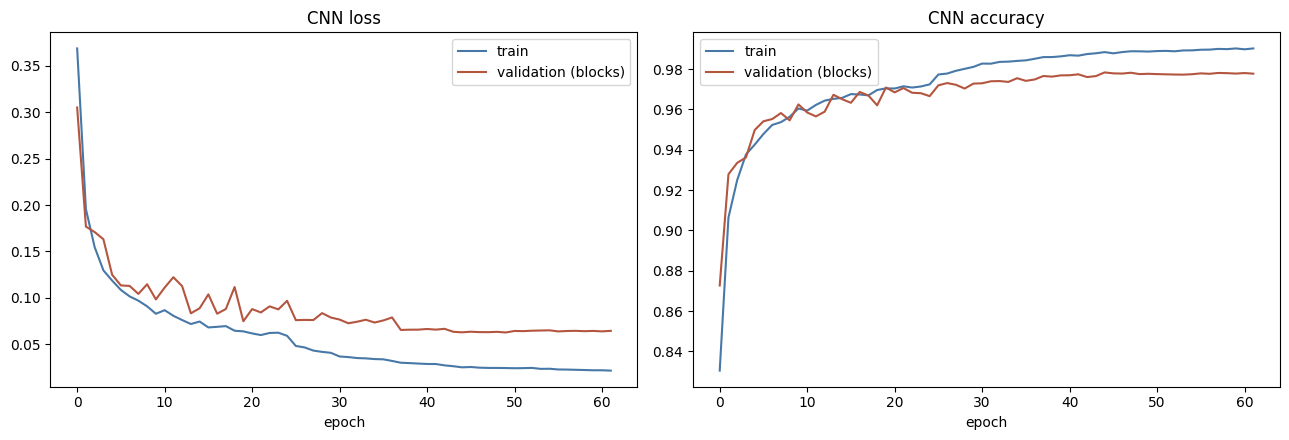

In [22]:
def build_cnn(shape, n_out=len(ORDER), seed=SEED):
    tf.random.set_seed(seed)
    m = keras.Sequential([
        layers.Input(shape=shape),
        layers.Conv2D(32, 3, activation="relu", padding="valid"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, activation="relu", padding="valid"),
        layers.BatchNormalization(),
        layers.Flatten(),
        layers.Dense(64, activation="relu"), layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dense(n_out, activation="softmax"),
    ], name="cnn")
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

tick("training CNN")
cnn = build_cnn(Ptr.shape[1:])
cnn.summary()
chist = cnn.fit(Ptr[~is_val_p], ytr_p[~is_val_p],
                validation_data=(Ptr[is_val_p], ytr_p[is_val_p]),
                epochs=EPOCHS, batch_size=BATCH, class_weight=CLASS_W,
                callbacks=CB(), verbose=0)
tick(f"stopped after {len(chist.history['loss'])} epochs")

ch = chist.history
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ch["loss"], label="train", color="#4878A8")
axes[0].plot(ch["val_loss"], label="validation (blocks)", color="#B4553F")
axes[0].set_title("CNN loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(ch["accuracy"], label="train", color="#4878A8")
axes[1].plot(ch["val_accuracy"], label="validation (blocks)", color="#B4553F")
axes[1].set_title("CNN accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
fig.tight_layout(); fig.savefig(p_out("cnn_training_curve.png"), dpi=170); plt.show()
pd.DataFrame(ch).to_csv(p_out("cnn_training_history.csv"), index=False)

## Stage 9 — CNN holdout performance

In [23]:
cnn_pred = cnn.predict(Pte, batch_size=1024, verbose=0).argmax(1)
rows = [scores(yte_p, cnn_pred, "CNN holdout (all)")]
reg_te = test[REGION].to_numpy()[ord_te]
for r in sorted(np.unique(reg_te)):
    m = reg_te == r
    rows.append(scores(yte_p[m], cnn_pred[m], f"CNN holdout Region {r}"))
cnn_res = pd.DataFrame(rows)
cnn_res.to_csv(p_out("cnn_holdout_scores.csv"), index=False)

cmc = pd.DataFrame(confusion_matrix(yte_p, cnn_pred, labels=range(len(ORDER))),
                   index=[f"true_{c}" for c in ORDER],
                   columns=[f"pred_{c}" for c in ORDER])
cmc.to_csv(p_out("cnn_holdout_confusion.csv"))
print("CNN recall per class (%):")
print((cmc.div(cmc.sum(axis=1), axis=0)*100).round(1).to_string())
cnn_res.round(4)

CNN recall per class (%):
         pred_N  pred_S3  pred_S2  pred_S1
true_N     98.4      1.6      0.0      0.0
true_S3     1.0     96.8      2.2      0.0
true_S2     0.0      2.3     97.5      0.2
true_S1     0.0      0.0      0.1     99.9


,subset,n,accuracy,macroF1,kappa,kappa_quadratic,within_one
0,CNN holdout (all),72026,0.9764,0.9794,0.9654,0.9840,1.0
1,CNN holdout Region I,24685,0.9732,0.9762,0.9619,0.9851,1.0
2,CNN holdout Region II,47341,0.9780,0.9777,0.9670,0.9830,1.0


## Stage 10 — Does spatial context help?

The architectural test. Both models are evaluated on the **same holdout cells** (the CNN's
ordering, so the comparison is exact), one seeing only the centre cell, the other seeing
its `k × k` neighbourhood.

In [24]:
ann_on_same = ann.predict(Xte[ord_te], batch_size=4096, verbose=0).argmax(1)
comp = pd.DataFrame([
    scores(yte_p, ann_on_same, f"ANN (centre cell only)"),
    scores(yte_p, cnn_pred,    f"CNN ({PATCH}x{PATCH} neighbourhood)"),
])
comp["n_params"] = [ann.count_params(), cnn.count_params()]
comp.to_csv(p_out("ann_vs_cnn.csv"), index=False)

d = comp.loc[1, "macroF1"] - comp.loc[0, "macroF1"]
print(f"\nCNN minus ANN, macro-F1: {d:+.4f}")
print(f"models agree on {100*np.mean(ann_on_same == cnn_pred):.2f}% of holdout cells")
comp.round(4)


CNN minus ANN, macro-F1: -0.0094
models agree on 97.94% of holdout cells


,subset,n,accuracy,macroF1,kappa,kappa_quadratic,within_one,n_params
0,ANN (centre cell only),72026,0.9881,0.9889,0.9826,0.992,1.0,12644
1,CNN (7x7 neighbourhood),72026,0.9764,0.9794,0.9654,0.984,1.0,60932


In [28]:
# ANN trained on exactly the CNN's cells — removes the sample-size confound
sc2 = StandardScaler().fit(train[FEATURES].iloc[ord_tr])
m2 = build_mlp(len(FEATURES))
m2.fit(sc2.transform(train[FEATURES].iloc[ord_tr]).astype("float32"), ytr_p,
       validation_data=(sc2.transform(train[FEATURES].iloc[ord_tr[is_val_p]]).astype("float32"),
                        ytr_p[is_val_p]),
       epochs=EPOCHS, batch_size=BATCH, class_weight=CLASS_W,
       callbacks=CB(), verbose=0)
p2 = m2.predict(sc2.transform(test[FEATURES]).astype("float32"),
                batch_size=4096, verbose=0).argmax(1)
fair = pd.DataFrame([
    scores(yte_p, p2[ord_te], f"ANN, {len(ord_tr):,} cells (matched)"),
    scores(yte_p, cnn_pred,   f"CNN, {len(ord_tr):,} cells"),
])
fair.to_csv(p_out("ann_vs_cnn_matched.csv"), index=False)
fair.round(4)

,subset,n,accuracy,macroF1,kappa,kappa_quadratic,within_one
0,"ANN, 103,236 cells (matched)",72026,0.9868,0.9873,0.9807,0.9911,1.0
1,"CNN, 103,236 cells",72026,0.9764,0.9794,0.9654,0.9840,1.0


In [29]:
# ---- ANN-CNN hybrid: patch branch + tabular branch -----------------------
tick("training ANN-CNN hybrid")

Xtr_p, Xte_p = Xtr[ord_tr], Xte[ord_te]      # tabular aligned to patch order

def build_hybrid(patch_shape, n_tab, n_out=len(ORDER), seed=SEED):
    tf.random.set_seed(seed)
    pin = layers.Input(shape=patch_shape, name="patch")
    p = layers.Conv2D(32, 3, activation="relu")(pin)
    p = layers.BatchNormalization()(p)
    p = layers.Conv2D(64, 3, activation="relu")(p)
    p = layers.BatchNormalization()(p)
    p = layers.Flatten()(p)
    p = layers.Dense(32, activation="relu", name="patch_embed")(p)

    tin = layers.Input(shape=(n_tab,), name="tabular")
    t = layers.Dense(128, activation="relu")(tin)
    t = layers.BatchNormalization()(t)
    t = layers.Dropout(0.3)(t)
    t = layers.Dense(32, activation="relu", name="tab_embed")(t)

    z = layers.Concatenate()([p, t])
    z = layers.Dense(32, activation="relu")(z)
    z = layers.Dropout(0.2)(z)
    out = layers.Dense(n_out, activation="softmax")(z)

    m = keras.Model([pin, tin], out, name="ann_cnn")
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

hyb = build_hybrid(Ptr.shape[1:], len(FEATURES))
hyb.summary()
hhist = hyb.fit(
    {"patch": Ptr[~is_val_p], "tabular": Xtr_p[~is_val_p]}, ytr_p[~is_val_p],
    validation_data=({"patch": Ptr[is_val_p], "tabular": Xtr_p[is_val_p]},
                     ytr_p[is_val_p]),
    epochs=EPOCHS, batch_size=BATCH, class_weight=CLASS_W,
    callbacks=CB(), verbose=0)
tick(f"stopped after {len(hhist.history['loss'])} epochs")

hyb_pred = hyb.predict({"patch": Pte, "tabular": Xte_p},
                       batch_size=1024, verbose=0).argmax(1)

[1764.3 min] training ANN-CNN hybrid


Model: "ann_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ patch (InputLayer)  │ (None, 7, 7, 10)  │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 5, 5, 32)  │      2,912 │ patch[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 5, 5, 32)  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tabular             │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 3, 3, 64)  │     18,496 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 128)       │      1,408 │ tabular[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 3, 3, 64)  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_7[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 576)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embed (Dense) │ (None, 32)        │     18,464 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tab_embed (Dense)   │ (None, 32)        │      4,128 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ patch_embed[0][0… │
│ (Concatenate)       │                   │            │ tab_embed[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 32)        │      2,080 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 32)        │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 4)         │        132 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 48,516 (189.52 KB)

 Trainable params: 48,068 (187.77 KB)

 Non-trainable params: 448 (1.75 KB)

[1765.5 min] stopped after 31 epochs


In [30]:
# ---- does the patch branch contribute anything? --------------------------
shuf = np.random.default_rng(SEED).permutation(len(Pte))
hyb_shuf = hyb.predict({"patch": Pte[shuf], "tabular": Xte_p},
                       batch_size=1024, verbose=0).argmax(1)
hyb_zero = hyb.predict({"patch": np.zeros_like(Pte), "tabular": Xte_p},
                       batch_size=1024, verbose=0).argmax(1)

hyb_res = pd.DataFrame([
    scores(yte_p, ann_on_same, "ANN  (tabular only)"),
    scores(yte_p, cnn_pred,    "CNN  (patch only)"),
    scores(yte_p, hyb_pred,    "ANN-CNN hybrid"),
    scores(yte_p, hyb_shuf,    "  hybrid, patches shuffled"),
    scores(yte_p, hyb_zero,    "  hybrid, patches zeroed"),
])
hyb_res.to_csv(p_out("hybrid_branch_ablation.csv"), index=False)
hyb.save(p_out("ann_cnn_hybrid.keras"))
print(f"\nhybrid minus ANN: {hyb_res.loc[2,'macroF1'] - hyb_res.loc[0,'macroF1']:+.4f}")
print(f"cost of shuffling patches: "
      f"{hyb_res.loc[3,'macroF1'] - hyb_res.loc[2,'macroF1']:+.4f}")
hyb_res.round(4)


hybrid minus ANN: -0.0157
cost of shuffling patches: -0.5521


,subset,n,accuracy,macroF1,kappa,kappa_quadratic,within_one
0,ANN (tabular only),72026,0.9881,0.9889,0.9826,0.9920,1.0000
1,CNN (patch only),72026,0.9764,0.9794,0.9654,0.9840,1.0000
2,ANN-CNN hybrid,72026,0.9711,0.9732,0.9578,0.9805,1.0000
3,"hybrid, patches shuffled",72026,0.5606,0.4211,0.3510,0.4735,0.9094
4,"hybrid, patches zeroed",72026,0.6210,0.3907,0.4295,0.5600,0.9738


In [31]:
h = PATCH // 2
centre = Pte[:, h, h, :]                     # true centre-cell values

# (a) neighbourhood removed — every cell in the patch set to the centre value
P_const = np.repeat(np.repeat(centre[:, None, None, :], PATCH, 1), PATCH, 2)

# (b) neighbourhood randomised — someone else's surroundings, own centre restored
P_rand = Pte[shuf].copy()
P_rand[:, h, h, :] = centre

pr_const = hyb.predict({"patch": P_const, "tabular": Xte_p},
                       batch_size=1024, verbose=0).argmax(1)
pr_rand  = hyb.predict({"patch": P_rand,  "tabular": Xte_p},
                       batch_size=1024, verbose=0).argmax(1)

fix = pd.DataFrame([
    scores(yte_p, hyb_pred, "hybrid, true patches"),
    scores(yte_p, pr_const, "  neighbourhood removed, centre kept"),
    scores(yte_p, pr_rand,  "  neighbourhood randomised, centre kept"),
    scores(yte_p, hyb_shuf, "  whole patch shuffled (centre lost) — confounded"),
])
fix.to_csv(p_out("hybrid_neighbourhood_ablation.csv"), index=False)
fix.round(4)

,subset,n,accuracy,macroF1,kappa,kappa_quadratic,within_one
0,"hybrid, true patches",72026,0.9711,0.9732,0.9578,0.9805,1.0000
1,"neighbourhood removed, centre kept",72026,0.9737,0.9753,0.9616,0.9822,1.0000
2,"neighbourhood randomised, centre kept",72026,0.7542,0.6067,0.6352,0.7949,0.9930
3,whole patch shuffled (centre lost) — confounded,72026,0.5606,0.4211,0.3510,0.4735,0.9094


### How to read it

- **CNN ≈ ANN (within ~0.005)** — the expected outcome. The FAO label is a pointwise
  function of the centre cell, so neighbourhood context carries no additional information.
  Report it: *spatial context did not improve classification, consistent with a target
  defined pointwise from the centre cell's own attributes; the convolutional architecture
  is therefore not warranted for this formulation.*
- **CNN clearly better** — would mean neighbourhood structure correlates with the label
  beyond the centre cell, most plausibly through smoothing of noisy 250 m soil inputs.
  Worth investigating rather than just reporting.
- **CNN clearly worse** — likely under-training or too small a sample; check whether its
  validation loss was still falling when early stopping fired.

## Stage 11 — Permutation importance and ALE (ANN)

Permutation is done manually rather than through scikit-learn, to avoid wrapping a Keras
model in an estimator interface. ALE uses the same expected-suitability response as the
tree notebooks, so the curves are directly comparable.

[  89.3 min] permutation importance (ANN)


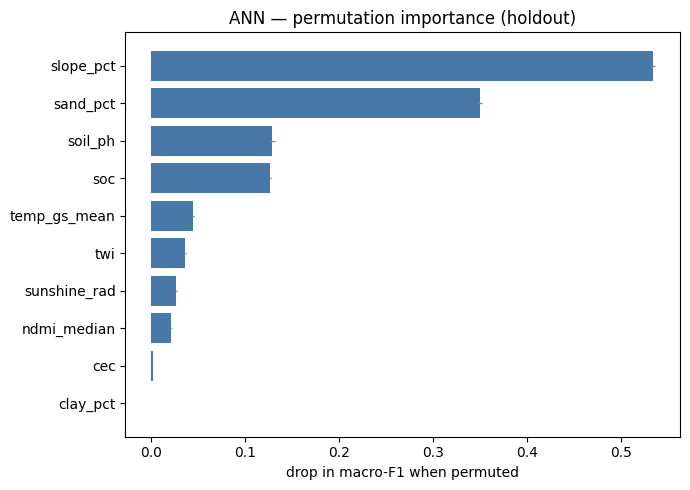

,feature,importance,sd
0,slope_pct,0.53396,0.00208
1,sand_pct,0.34978,0.00216
2,soil_ph,0.12891,0.00273
3,soc,0.12674,0.00094
4,temp_gs_mean,0.04440,0.00104
5,twi,0.03615,0.00091
6,sunshine_rad,0.02657,0.00107
7,ndmi_median,0.02182,0.00021
8,cec,0.00217,0.00027
9,clay_pct,-0.00000,0.00027


In [25]:
tick("permutation importance (ANN)")
base = f1_score(yte, ann_pred, average="macro")
rows = []
rs = np.random.default_rng(SEED)
for i, f in enumerate(FEATURES):
    drops = []
    for _ in range(5):
        Xp = Xte.copy()
        Xp[:, i] = Xp[rs.permutation(len(Xp)), i]
        drops.append(base - f1_score(
            yte, ann.predict(Xp, batch_size=8192, verbose=0).argmax(1),
            average="macro"))
    rows.append(dict(feature=f, importance=np.mean(drops), sd=np.std(drops)))
imp = pd.DataFrame(rows).sort_values("importance", ascending=False).reset_index(drop=True)
imp.to_csv(p_out("ann_permutation_importance.csv"), index=False)

t = imp.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(t["feature"], t["importance"], xerr=t["sd"], color="#4878A8",
        error_kw=dict(ecolor="#888", lw=1))
ax.set_xlabel("drop in macro-F1 when permuted")
ax.set_title("ANN — permutation importance (holdout)")
fig.tight_layout(); fig.savefig(p_out("ann_permutation_importance.png"), dpi=170)
plt.show()
imp.round(5)

[  89.4 min] ALE (ANN)


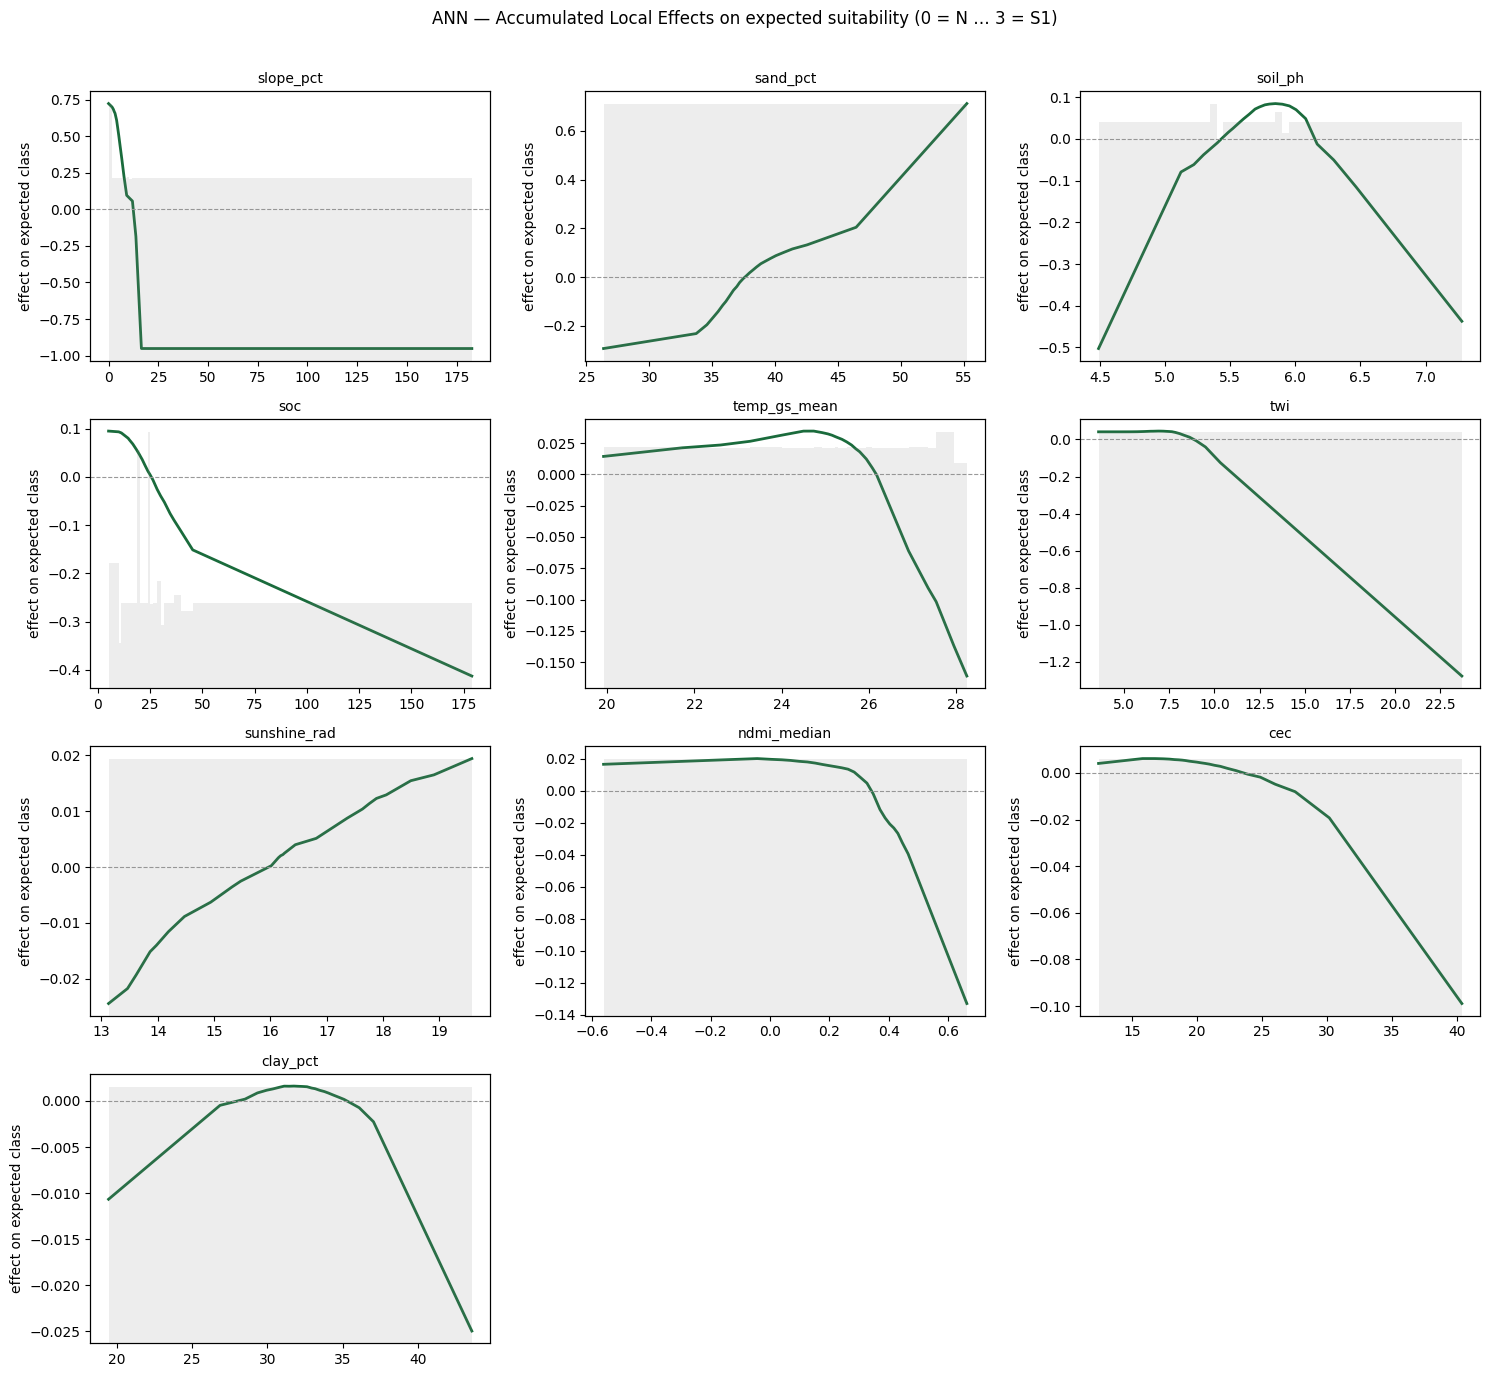

In [26]:
def expected_level(X):
    return ann.predict(X, batch_size=8192, verbose=0) @ np.arange(len(ORDER), dtype=float)

def ale_1d(Xs, j, bins=24, sample=20_000, seed=SEED):
    rs = np.random.default_rng(seed)
    if len(Xs) > sample:
        Xs = Xs[rs.choice(len(Xs), sample, replace=False)]
    v = Xs[:, j]
    q = np.unique(np.quantile(v, np.linspace(0, 1, bins + 1)))
    if len(q) < 3:
        return None
    k = np.clip(np.searchsorted(q, v, side="left") - 1, 0, len(q) - 2)
    eff = np.zeros(len(q)-1); cnt = np.zeros(len(q)-1)
    for b in range(len(q)-1):
        m = k == b
        if not m.any():
            continue
        lo, hi = Xs[m].copy(), Xs[m].copy()
        lo[:, j], hi[:, j] = q[b], q[b+1]
        eff[b] = np.mean(expected_level(hi) - expected_level(lo))
        cnt[b] = m.sum()
    ale = np.concatenate([[0.0], np.cumsum(eff)])
    centre = np.sum((ale[:-1]+ale[1:])/2 * cnt) / max(cnt.sum(), 1)
    return q, ale - centre, cnt

tick("ALE (ANN)")
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, f in zip(axes.ravel(), imp["feature"].tolist()):
    j = FEATURES.index(f)
    out = ale_1d(Xte, j)
    if out is None:
        ax.set_visible(False); continue
    q, a, c = out
    # back-transform the x axis to original units
    qx = q * np.sqrt(scaler.var_[j]) + scaler.mean_[j]
    ax.plot(qx, a, lw=2, color="#1a6b3c")
    ax.axhline(0, color="#999", lw=0.8, ls="--")
    ax2 = ax.twinx(); ax2.bar((qx[:-1]+qx[1:])/2, c, width=np.diff(qx),
                              alpha=0.15, color="#888"); ax2.set_yticks([])
    ax.set_title(f, fontsize=10); ax.set_ylabel("effect on expected class")
for ax in axes.ravel()[len(imp):]:
    ax.set_visible(False)
fig.suptitle("ANN — Accumulated Local Effects on expected suitability "
             "(0 = N … 3 = S1)", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(p_out("ann_ale_all.png"), dpi=170); plt.show()

## Stage 12 — Five-model comparison

In [27]:
LR  = dict(cv_macroF1=0.8580, holdout_macroF1=0.8370, holdout_kappa=0.7740,
           holdout_accuracy=0.8450, within_one=0.9985)
RF  = dict(cv_macroF1=0.9706, holdout_macroF1=0.9774, holdout_kappa=0.9636,
           holdout_accuracy=0.9752, within_one=1.0000)
XGB = dict(cv_macroF1=0.9846, holdout_macroF1=0.9907, holdout_kappa=0.9863,
           holdout_accuracy=0.9907, within_one=1.0000)   # update to the 1000-round run

a = ann_res[ann_res["subset"] == "ANN holdout (all)"].iloc[0]
c = cnn_res[cnn_res["subset"] == "CNN holdout (all)"].iloc[0]
cmp = pd.DataFrame([
    dict(model="Ordinal LR (baseline)", **LR),
    dict(model="Random forest", **RF),
    dict(model="XGBoost", **XGB),
    dict(model="ANN (MLP)", cv_macroF1=ann_cv.loc["mean", "macroF1"],
         holdout_macroF1=a["macroF1"], holdout_kappa=a["kappa"],
         holdout_accuracy=a["accuracy"], within_one=a["within_one"]),
    dict(model=f"CNN ({PATCH}x{PATCH} patch)", cv_macroF1=np.nan,
         holdout_macroF1=c["macroF1"], holdout_kappa=c["kappa"],
         holdout_accuracy=c["accuracy"], within_one=c["within_one"]),
])
cmp.to_csv(p_out("model_comparison_5way.csv"), index=False)

ann.save(p_out("ann_model.keras")); cnn.save(p_out("cnn_model.keras"))
import joblib; joblib.dump({"scaler": scaler, "features": FEATURES,
                            "order": ORDER, "patch": PATCH},
                           p_out("nn_preprocessing.joblib"))
print("models and scaler saved")
cmp.round(4)

models and scaler saved


,model,cv_macroF1,holdout_macroF1,holdout_kappa,holdout_accuracy,within_one
0,Ordinal LR (baseline),0.8580,0.8370,0.7740,0.8450,0.9985
1,Random forest,0.9706,0.9774,0.9636,0.9752,1.0000
2,XGBoost,0.9846,0.9907,0.9863,0.9907,1.0000
3,ANN (MLP),0.9821,0.9889,0.9826,0.9881,1.0000
4,CNN (7x7 patch),NaN,0.9794,0.9654,0.9764,1.0000


### Closing notes

- **Delete `nn_work/`** when finished — the grid memmaps are about 6 GB and are rebuilt
  from `labeled/` on demand.
- The scaler is saved alongside the models; wall-to-wall prediction must apply the **same
  training-set scaler**, never one refitted on the full grid.
- The CNN's cross-validation entry is left blank: refitting it five times over patch
  arrays is expensive, and the ANN-versus-CNN comparison in Stage 10 is on identical
  holdout cells, which is the comparison that matters.
- Whatever the ranking, the framing is unchanged. All five models reproduce a
  deterministic rule from its own inputs; accuracy measures fidelity of the surrogate,
  not agronomic discovery.